# UCS420 Cognitive Computing
## Assignment 10 - Heart Health Information Assistant (even roll number)

In [1]:
# N Soma Sekhar
# Roll No: 1024170194

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

True

### 1. Labelled corpus

In [2]:
data = [
    ("What are the symptoms of a heart attack?", "symptoms"),
    ("Why do I feel chest discomfort when I climb stairs?", "symptoms"),
    ("Is pain in the left arm a sign of heart problems?", "symptoms"),
    ("What are the warning signs of heart disease?", "symptoms"),
    ("Can heart problems cause swelling in the legs?", "symptoms"),
    ("I get breathless while walking, is it my heart?", "symptoms"),
    ("Do women have different heart attack symptoms?", "symptoms"),
    ("Is a fast heartbeat or palpitations dangerous?", "symptoms"),
    ("What does angina feel like?", "symptoms"),
    ("Can tiredness and dizziness be signs of a weak heart?", "symptoms"),
    ("How do I know if my heart is not healthy?", "symptoms"),
    ("What signs show heart failure?", "symptoms"),
    ("My chest hurts and feels heavy, what could it be?", "symptoms"),
    ("Is sweating with chest pain a heart symptom?", "symptoms"),
    ("Why does my heart beat irregularly?", "symptoms"),
    ("Can jaw or back pain mean a heart problem?", "symptoms"),

    ("What foods are good for the heart?", "diet"),
    ("How much salt should I eat per day for my heart?", "diet"),
    ("Is ghee or butter bad for the heart?", "diet"),
    ("Which oil is best for heart health?", "diet"),
    ("Are eggs safe for heart patients?", "diet"),
    ("What should I eat to keep my heart healthy?", "diet"),
    ("Is fried food bad for my heart?", "diet"),
    ("Are nuts and fish good for the heart?", "diet"),
    ("Should I avoid red meat for heart health?", "diet"),
    ("Is coffee or tea harmful for the heart?", "diet"),
    ("What is a heart healthy breakfast?", "diet"),
    ("Does sugar affect heart health?", "diet"),
    ("How much oil should I use in cooking for a healthy heart?", "diet"),
    ("Is eating junk food every day bad for the heart?", "diet"),
    ("Which fruits and vegetables help the heart?", "diet"),
    ("Is a vegetarian diet better for the heart?", "diet"),

    ("What is a normal blood pressure reading?", "blood_pressure"),
    ("How can I lower my high blood pressure?", "blood_pressure"),
    ("What does 140/90 blood pressure mean?", "blood_pressure"),
    ("How often should I check my blood pressure?", "blood_pressure"),
    ("What is hypertension?", "blood_pressure"),
    ("How do I measure BP at home correctly?", "blood_pressure"),
    ("Does stress increase blood pressure?", "blood_pressure"),
    ("Why is high BP called a silent killer?", "blood_pressure"),
    ("Is low blood pressure a problem?", "blood_pressure"),
    ("What is systolic and diastolic pressure?", "blood_pressure"),
    ("Can high blood pressure damage the heart?", "blood_pressure"),
    ("What BP level is too high?", "blood_pressure"),
    ("My BP readings are high in the morning, why?", "blood_pressure"),
    ("Can reducing salt bring down my BP?", "blood_pressure"),
    ("What is the target blood pressure for adults?", "blood_pressure"),
    ("Which BP monitor should I buy for home?", "blood_pressure"),

    ("What is a normal cholesterol level?", "cholesterol"),
    ("What is the difference between LDL and HDL?", "cholesterol"),
    ("How can I reduce my bad cholesterol?", "cholesterol"),
    ("What is a lipid profile test?", "cholesterol"),
    ("How often should I check cholesterol?", "cholesterol"),
    ("Why is high cholesterol bad for the heart?", "cholesterol"),
    ("What are triglycerides?", "cholesterol"),
    ("Can young people have high cholesterol?", "cholesterol"),
    ("Does cholesterol block the arteries?", "cholesterol"),
    ("What is good cholesterol?", "cholesterol"),
    ("What LDL value is considered high?", "cholesterol"),
    ("Is high cholesterol genetic?", "cholesterol"),
    ("My LDL is 160, is that bad?", "cholesterol"),
    ("How do I raise my HDL cholesterol?", "cholesterol"),
    ("Which foods increase cholesterol?", "cholesterol"),
    ("Can cholesterol be high even if I am thin?", "cholesterol"),

    ("How much exercise is good for the heart?", "exercise"),
    ("Is walking daily good for heart health?", "exercise"),
    ("Can heart patients go to the gym?", "exercise"),
    ("Which exercises make the heart stronger?", "exercise"),
    ("Is running good for my heart?", "exercise"),
    ("Does yoga help the heart?", "exercise"),
    ("Is it safe to exercise after a heart attack?", "exercise"),
    ("How many steps a day are good for the heart?", "exercise"),
    ("Can swimming or cycling improve heart health?", "exercise"),
    ("What is cardio exercise?", "exercise"),
    ("Should I check my pulse while working out?", "exercise"),
    ("How long should I workout every week?", "exercise"),
    ("How much should I walk every day?", "exercise"),
    ("Is brisk walking enough exercise for the heart?", "exercise"),
    ("What is a good heart rate during exercise?", "exercise"),
    ("Can lifting weights hurt my heart?", "exercise"),

    ("What are statins used for?", "medication"),
    ("What are the side effects of statins?", "medication"),
    ("Should I take aspirin every day for my heart?", "medication"),
    ("What do beta blockers do?", "medication"),
    ("Can I stop my blood pressure tablets if I feel fine?", "medication"),
    ("When should I take my heart medicine?", "medication"),
    ("What happens if I miss a dose of my heart tablet?", "medication"),
    ("What is a blood thinner?", "medication"),
    ("Which medicines are used for heart disease?", "medication"),
    ("Can I take painkillers with heart medicines?", "medication"),
    ("What is nitroglycerin used for?", "medication"),
    ("Do I need to take heart medicine for life?", "medication"),
    ("Can I take aspirin and statins together?", "medication"),
    ("Why did my doctor give me a blood thinner?", "medication"),
    ("Do statins damage the liver?", "medication"),
    ("Is it okay to skip my BP medicine for a day?", "medication"),
]

df = pd.DataFrame(data, columns=['query', 'intent'])
print(len(df))
print(df['intent'].value_counts())

96
intent
symptoms          16
diet              16
blood_pressure    16
cholesterol       16
exercise          16
medication        16
Name: count, dtype: int64


### 2. Taxonomy

In [3]:
taxonomy = {
    "Understanding Heart Health": ["Symptoms", "Heart Conditions"],
    "Risk Factors": ["Blood Pressure", "Cholesterol"],
    "Lifestyle": ["Diet", "Exercise"],
    "Treatment and Safety": ["Medication", "Emergencies"],
}

for k in taxonomy:
    print(k)
    for s in taxonomy[k]:
        print("    -", s)

Understanding Heart Health
    - Symptoms
    - Heart Conditions
Risk Factors
    - Blood Pressure
    - Cholesterol
Lifestyle
    - Diet
    - Exercise
Treatment and Safety
    - Medication
    - Emergencies


### 3. Concepts and relationships

In [4]:
concepts = ["Heart", "Arteries", "Blood Pressure", "Cholesterol", "LDL", "HDL", "Heart Attack",
            "Exercise", "Salt", "Statins", "Smoking", "Plaque"]

relations = [
    ("Heart", "pumps blood through", "Arteries"),
    ("LDL", "is a type of", "Cholesterol"),
    ("HDL", "is a type of", "Cholesterol"),
    ("LDL", "forms", "Plaque"),
    ("Plaque", "narrows", "Arteries"),
    ("Plaque", "can cause", "Heart Attack"),
    ("Salt", "increases", "Blood Pressure"),
    ("Blood Pressure", "strains", "Heart"),
    ("Exercise", "lowers", "Blood Pressure"),
    ("Exercise", "raises", "HDL"),
    ("Statins", "lower", "LDL"),
    ("Smoking", "damages", "Arteries"),
]

print(len(concepts), "concepts")
print(len(relations), "relations")
for r in relations:
    print(r[0], "-->", r[1], "-->", r[2])

12 concepts
12 relations
Heart --> pumps blood through --> Arteries
LDL --> is a type of --> Cholesterol
HDL --> is a type of --> Cholesterol
LDL --> forms --> Plaque
Plaque --> narrows --> Arteries
Plaque --> can cause --> Heart Attack
Salt --> increases --> Blood Pressure
Blood Pressure --> strains --> Heart
Exercise --> lowers --> Blood Pressure
Exercise --> raises --> HDL
Statins --> lower --> LDL
Smoking --> damages --> Arteries


### 4. Preprocessing

In [5]:
sw = stopwords.words('english')
lem = WordNetLemmatizer()

def preprocess(text):
    text = text.lower()
    tokens = word_tokenize(text)
    words = []
    for t in tokens:
        if t.isalnum() and t not in sw:
            words.append(lem.lemmatize(t))
    return " ".join(words)

print(preprocess("What are the symptoms of a heart attack?"))
print(preprocess("How can I reduce my bad cholesterol?"))

df['clean'] = df['query'].apply(preprocess)
df.head()

symptom heart attack
reduce bad cholesterol


,query,intent,clean
0,What are the symptoms of a heart attack?,symptoms,symptom heart attack
1,Why do I feel chest discomfort when I climb st...,symptoms,feel chest discomfort climb stair
2,Is pain in the left arm a sign of heart problems?,symptoms,pain left arm sign heart problem
3,What are the warning signs of heart disease?,symptoms,warning sign heart disease
4,Can heart problems cause swelling in the legs?,symptoms,heart problem cause swelling leg


### 5. TF-IDF and classifier

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

x_train, x_test, y_train, y_test = train_test_split(df['clean'], df['intent'], test_size=0.25, random_state=1, stratify=df['intent'])

vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5))
xtr = vec.fit_transform(x_train)
xte = vec.transform(x_test)

nbm = MultinomialNB()
nbm.fit(xtr, y_train)
print("Naive Bayes accuracy:", nbm.score(xte, y_test))

lr = LogisticRegression(C=10, max_iter=1000)
lr.fit(xtr, y_train)
print("Logistic Regression accuracy:", lr.score(xte, y_test))

Naive Bayes accuracy: 0.75
Logistic Regression accuracy: 0.7916666666666666


### 6. Evaluation

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

pred = lr.predict(xte)
print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, average='macro'))
print("Recall:", recall_score(y_test, pred, average='macro'))
print("F1:", f1_score(y_test, pred, average='macro'))
print(classification_report(y_test, pred))

Accuracy: 0.7916666666666666
Precision: 0.8833333333333333
Recall: 0.7916666666666666
F1: 0.791005291005291
                precision    recall  f1-score   support

blood_pressure       1.00      0.75      0.86         4
   cholesterol       0.80      1.00      0.89         4
          diet       0.50      1.00      0.67         4
      exercise       1.00      0.50      0.67         4
    medication       1.00      1.00      1.00         4
      symptoms       1.00      0.50      0.67         4

      accuracy                           0.79        24
     macro avg       0.88      0.79      0.79        24
  weighted avg       0.88      0.79      0.79        24



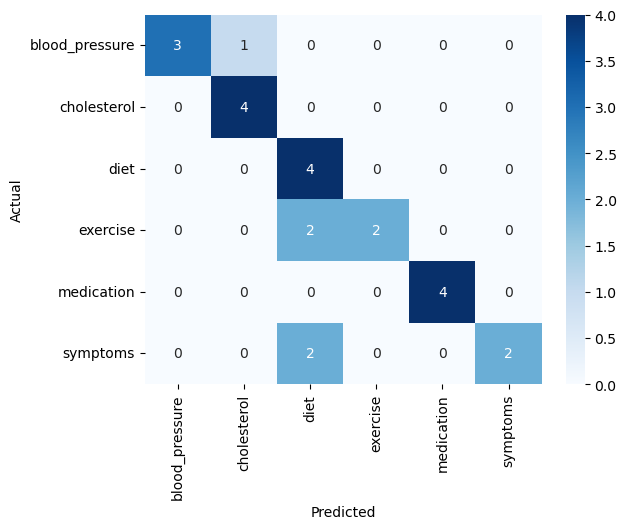

In [8]:
cm = confusion_matrix(y_test, pred, labels=lr.classes_)
sns.heatmap(cm, annot=True, xticklabels=lr.classes_, yticklabels=lr.classes_, cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [9]:
vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5))
X_all = vec.fit_transform(df['clean'])
lr = LogisticRegression(C=10, max_iter=1000)
lr.fit(X_all, df['intent'])

vocab = []
for c in df['clean']:
    for w in c.split():
        if w not in vocab:
            vocab.append(w)
print(len(vocab))

186


The test set is small (24 queries), so these scores change a lot with only 1 or 2 mistakes. After evaluating, I trained the model again on all the queries so the assistant can use all of them.

### 7. Knowledge base

In [10]:
kb = {
    "symptoms": "Common heart attack symptoms are chest pain or pressure, pain spreading to the arm, jaw or back, shortness of breath, cold sweat, nausea and dizziness. Swelling in the legs and getting breathless easily can be signs of heart failure. See a doctor if you notice these.",
    "diet": "A heart healthy diet has lots of vegetables, fruits, whole grains, pulses, nuts and fish. Keep salt below 5 g a day (about 1 teaspoon) and limit fried food, ghee/butter, red meat, sweets and sugary drinks.",
    "blood_pressure": "Normal blood pressure is below 120/80 mmHg. 130/80 or above is high blood pressure (hypertension). Reduce salt, exercise, keep a healthy weight, avoid smoking and alcohol, and check BP regularly at home.",
    "cholesterol": "LDL is the bad cholesterol that builds plaque in the arteries, and HDL is the good cholesterol. For most adults LDL should be below 100 mg/dL. A lipid profile blood test checks LDL, HDL and triglycerides. Adults should get it done every 4 to 6 years, or more often if they have risk factors.",
    "exercise": "Do at least 150 minutes of moderate exercise every week, like brisk walking, cycling or swimming, plus some strength training 2 days a week. Heart patients should ask their doctor before starting a new exercise plan.",
    "medication": "Statins lower LDL cholesterol, beta blockers slow the heart rate and lower BP, and blood thinners like aspirin help prevent clots. Only take aspirin daily if your doctor tells you to. Never stop heart medicines on your own.",
}

### 8. Rules

In [11]:
emergency_words = ["severe chest pain", "crushing", "heart attack now", "collapsed", "unconscious",
                   "fainted", "can't breathe", "cannot breathe", "not breathing", "stroke", "face drooping"]
other_topics = ["diabetes", "cancer", "asthma", "fever", "cough", "migraine", "skin", "tooth", "fracture", "covid", "eye"]
greetings = ["hi", "hello", "hey", "thanks", "thank you"]
disclaimer = "(This is general information, please consult a doctor.)"

def check_bp(q):
    m = re.search(r'(\d{2,3})\s*/\s*(\d{2,3})', q)
    if m:
        sys_bp = int(m.group(1))
        dia_bp = int(m.group(2))
        if sys_bp >= 180 or dia_bp >= 120:
            return "Your BP " + m.group(0) + " is very high (hypertensive crisis). Get medical help immediately, especially if you have chest pain, headache or breathlessness."
    return None

### 9. Assistant

In [12]:
def assistant(q):
    q_low = q.lower()

    for w in emergency_words:
        if w in q_low:
            return "EMERGENCY: Call 112 or 108 for an ambulance right now. If it is a heart attack, chew one aspirin only if you are not allergic, and stay calm until help arrives.", "emergency rule"

    bp = check_bp(q_low)
    if bp != None:
        return bp, "bp rule"

    if q_low.strip(" !.") in greetings:
        return "Hello! I am a heart health assistant. Ask me about symptoms, diet, blood pressure, cholesterol, exercise or medicines.", "greeting rule"

    for w in other_topics:
        if w in q_low.split():
            return "Sorry, I can only answer heart health questions. Please ask a doctor about this.", "unsupported rule"

    clean = preprocess(q)
    v = vec.transform([clean])
    known = False
    for w in clean.split():
        if w in vocab:
            known = True
    if known == False:
        return "Sorry, I can only answer heart health questions. Please ask a doctor about this.", "unsupported rule"

    probs = lr.predict_proba(v)[0]
    best = np.argmax(probs)
    intent = lr.classes_[best]
    conf = probs[best]

    if conf < 0.4:
        return "I am not sure what you mean (confidence " + str(round(conf, 2)) + "). Can you ask in a different way?", "low confidence rule"

    ans = kb[intent]
    if "stop" in q_low and ("medicine" in q_low or "tablet" in q_low):
        ans = ans + " Do not stop any medicine without asking your doctor."
    return ans + " " + disclaimer, intent + " (" + str(round(conf, 2)) + ")"

### 10. Testing

In [13]:
tests = ["What are the signs of a heart attack?",
         "Is eating too much salt bad for my heart?",
         "What is normal BP?",
         "How do I lower LDL cholesterol?",
         "Is jogging in the morning good for my heart?",
         "What are the side effects of statins?",
         "my chest feels tight and heavy when I run up the stairs",
         "how to treat a migraine",
         "is my heart okay",
         "My father has severe chest pain and is sweating",
         "my bp is 190/125",
         "Can I stop my BP tablets now?",
         "hello"]

for t in tests:
    ans, reason = assistant(t)
    print("Q:", t)
    print("Reason:", reason)
    print("A:", ans)
    print()

Q: What are the signs of a heart attack?
Reason: symptoms (0.84)
A: Common heart attack symptoms are chest pain or pressure, pain spreading to the arm, jaw or back, shortness of breath, cold sweat, nausea and dizziness. Swelling in the legs and getting breathless easily can be signs of heart failure. See a doctor if you notice these. (This is general information, please consult a doctor.)

Q: Is eating too much salt bad for my heart?
Reason: diet (0.8)
A: A heart healthy diet has lots of vegetables, fruits, whole grains, pulses, nuts and fish. Keep salt below 5 g a day (about 1 teaspoon) and limit fried food, ghee/butter, red meat, sweets and sugary drinks. (This is general information, please consult a doctor.)

Q: What is normal BP?
Reason: blood_pressure (0.45)
A: Normal blood pressure is below 120/80 mmHg. 130/80 or above is high blood pressure (hypertension). Reduce salt, exercise, keep a healthy weight, avoid smoking and alcohol, and check BP regularly at home. (This is general i

Results:
- Each intent query gets the correct topic.
- The differently worded query ("my chest feels tight...") was still classified correctly.
- The migraine question is unsupported, so the assistant refuses to answer.
- "is my heart okay" is too vague and has low confidence, so it asks the user to rephrase.
- Severe chest pain triggers the emergency rule.
- 190/125 triggers the BP rule.

### 11. Interactive interface

In [14]:
import ipywidgets as widgets
from IPython.display import display

box = widgets.Text(placeholder="Type your question")
btn = widgets.Button(description="Ask")
out = widgets.Output()

def on_click(b):
    with out:
        ans, reason = assistant(box.value)
        print("You:", box.value)
        print("Bot:", ans)
        print()
    box.value = ""

btn.on_click(on_click)
display(box, btn, out)

Text(value='', placeholder='Type your question')

Button(description='Ask', style=ButtonStyle())

Output()